# Description

The purpose of this notebook is to push our dataset to Hugging Face in a easy to setup format and use so that we can easily change models and processors and datasets and validate everything easily. Otherwise, adapting such bits to our cases is a nightmare

# Imports

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
from pathlib import Path
from typing import Iterator, Optional
import os
import datasets
import huggingface_hub
from datasets import Dataset, Features, Value, Image as HFImage, load_dataset
from tqdm import tqdm
from PIL import Image
from utils.preprocessing import load_images_from_npy
from dotenv import load_dotenv
import matplotlib.pyplot as plt

%matplotlib inline

/mnt/sam1/brexpert-mm/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()
HF_TOKEN = os.getenv('HF_TOKEN')

In [10]:
ds = load_dataset("jddomingues/brexpert-mm", split="train")

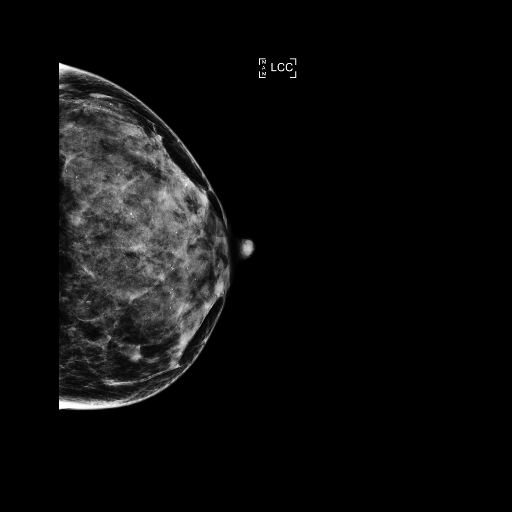

In [19]:
ds[1213]["image"]

# Load the current VQA dataset

In [ ]:
TRAIN_JSONL_PATH = "../../data/robust_vqa_split/vqa_train.jsonl"
VAL_JSONL_PATH = "../../data/robust_vqa_split/vqa_val.jsonl"
TEST_JSONL_PATH = "../../data/robust_vqa_split/vqa_test.jsonl"

TRAIN_CSV_PATH = "../../data/report_generation_split/all-rg-train.csv"
TEST_CSV_PATH = "../../data/report_generation_split/all-rg-test.csv"
VAL_CSV_PATH = "../../data/report_generation_split/all-rg-val.csv"

In [ ]:
train_vqa = pd.read_json(TRAIN_JSONL_PATH, lines=True)
train_csv = pd.read_csv(TRAIN_CSV_PATH)
train_csv["_memmap_idx"] = np.arange(len(train_csv), dtype=np.int64)

In [ ]:
merge_cols = [
    "id",
    "_memmap_idx",
    "birads",
    "original_birads",
    "modality",
    "dataset",
    "patient",
]
out = train_vqa.merge(
    train_csv[merge_cols],
    left_on="source_id",
    right_on="id",
    how="left",
    suffixes=("_vqa", "_rg"),
)

In [ ]:
out.head(2)

In [ ]:
out.iloc[0]["conversation"]

# Count Max Token Length Response

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
            "microsoft/biogpt",
            trust_remote_code=True,
        )

In [ ]:
min_length = 100
max_length = -1
all = []

# for row in tqdm(out.itertuples(), total=len(out)):
#     for round in row.conversation:
#         if round["role"] == "assistant":
#             toks = tokenizer(round["text"], add_special_tokens=False)["input_ids"]
#             if len(toks) < min_length:
#                 min_length = len(toks)
#             if len(toks) > max_length:
#                 max_length = len(toks)
#             all.append(len(toks))

In [ ]:
min_length, max_length, np.mean(all), np.median(all), np.std(all)

# Analyse current data and establish a plan for HF upload

In [ ]:
FEATURES = Features(
    {
        "image": HFImage(),
        "image_id": Value("string"),
        "birads": Value("string"),
        "original_birads": Value("string"),
        "modality": Value("string"),
        "dataset": Value("string"),
        "patient": Value("string"),
        "context": Value("string"),
        "n_turns": Value("int32"),

        "conversation": [
            {
                "question": Value("string"),
                "answer": Value("string"),
                "task_type": Value("string"),
                "scope": Value("string"),
                "field_id": Value("string"),
                "difficulty": Value("string"),
                "is_negative": Value("bool"),
            }
        ],
    }
)

In [ ]:
def to_uint8(img: np.ndarray) -> np.ndarray:
    img = img.astype(np.float32)
    lo, hi = float(img.min()), float(img.max())
    if hi <= lo:
        print(f"Warning: image has no variation (min={lo}, max={hi}). Returning zeros.")
        return np.zeros_like(img, dtype=np.uint8)
    return (((img - lo) / (hi - lo)) * 255.0).round().astype(np.uint8)

In [ ]:
def build_rows(shards: list, image_root: Path, skips: list = None) -> Iterator[dict]:
    for df in shards:
        for row in df.itertuples():
            img_path = image_root / row.image_path
            try:
                img = load_images_from_npy(str(img_path))[0]
                pil_img = Image.fromarray(to_uint8(img))
            except Exception as exc:
                print(f"[skip:load] {row.image_path}: {exc}")
                continue

            conv = row.conversation
            if len(conv) % 2 != 0:
                print(f"[skip:odd] {row.image_path}: {len(conv)} turns")
                continue

            turns = []
            for i in range(0, len(conv), 2):
                q, a = conv[i], conv[i + 1]
                turns.append({
                    "question": q["text"],
                    "answer": a["text"],
                    "task_type": a["task_type"],
                    "scope": a["scope"],
                    "field_id": a["field_id"],
                    "difficulty": a["difficulty"],
                    "is_negative": bool(a["is_negative"]),
                })

            yield {
                "image": pil_img,
                "image_id": str(row.image_path),
                "birads": row.birads,
                "original_birads": row.original_birads,
                "modality": row.modality,
                "dataset": row.dataset,
                "patient": row.patient,
                "context": row.context,
                "n_turns": len(turns),
                "conversation": turns,
            }

In [ ]:
def upload_data_hf(
    df,
    repo_id: str,
    split: str,
    commit_message: str,
    image_root: Path = Path(".."),
    token: Optional[str] = None,
    private: bool = True,
    num_proc: int = 8,
    max_shard_size: str = "500MB",
    dry_run: bool = False,
) -> Dataset:
    token = token or os.environ.get("HF_TOKEN")
    if token is None:
        raise RuntimeError("No HF token: set HF_TOKEN or pass token=")
    
    shards = [df.iloc[i::64] for i in range(64)]   # 64 shards, 8 workers
    ds = Dataset.from_generator(
        build_rows,
        gen_kwargs={"shards": shards, "image_root": image_root},
        features=FEATURES,
        num_proc=num_proc,
    )

 
    print(f"{len(ds)} images, {sum(ds['n_turns'])} QA pairs")
    print(f"~{ds.data.nbytes / 1e9:.1f} GB on disk before upload")
 
    if dry_run:
        return ds
 
    ds.push_to_hub(
        repo_id=repo_id,
        token=token,
        split=split,
        commit_message=commit_message,
        private=private,
        max_shard_size=max_shard_size,
    )
    return ds

In [ ]:
sample = out.sample(n=500, random_state=0)
upload_data_hf(
    sample,
    repo_id="jddomingues/brexpert-mm",
    split="train",
    commit_message="smoke test",
    private=True,
    num_proc=8,
)

d = load_dataset("jddomingues/brexpert-mm", split="train", download_mode="force_redownload")
c = d[0]["conversation"]
assert isinstance(c, list) and isinstance(c[0], dict), type(c)
print(c[0])
print(d[0]["image"].size, d[0]["image"].mode)

In [ ]:
from huggingface_hub import HfApi
api = HfApi(token=os.environ["HF_TOKEN"])
print(api.list_repo_files("jddomingues/brexpert-mm", repo_type="dataset"))

In [ ]:
from huggingface_hub import HfApi
api = HfApi(token=os.environ["HF_TOKEN"])
api.delete_repo("jddomingues/brexpert-mm", repo_type="dataset", missing_ok=True)

In [1]:
! rm -rf ~/.cache/huggingface/datasets/jddomingues___brexpert-mm

In [ ]:
ds = upload_data_hf(out, repo_id="jddomingues/brexpert-mm", split="train", commit_message="Initial upload of Brexpert-MM train split", token="", private=True, num_proc=8, max_shard_size="500MB", dry_run=True)
ds

In [ ]:
print(f"{ds.info.dataset_size / 1e9:.2f} GB")          # arrow bytes
per_row = ds.info.dataset_size / len(ds)
print(f"projected: {per_row * 291_059 / 1e9:.1f} GB")

In [ ]:
import numpy as np
sizes = np.array([len(b["bytes"]) for b in ds.data.column("image").to_pylist()])
mean, sd = sizes.mean(), sizes.std(ddof=1)
se = sd / np.sqrt(len(sizes))
print(f"{mean/1024:.0f} ± {se/1024:.0f} KB/img  (sd {sd/1024:.0f})")
print(f"projected {mean*291_059/1e9:.1f} GB  ±{1.96*se*291_059/1e9:.1f}")
print(f"p50 {np.percentile(sizes,50)/1024:.0f}  p99 {np.percentile(sizes,99)/1024:.0f} KB")

In [ ]:
sample = sample.assign(nbytes=sizes)
per_ds = sample.groupby("dataset").nbytes.mean()
proj = (out.dataset.value_counts() * per_ds).sum()
print(f"stratified projection: {proj/1e9:.1f} GB")

In [ ]:
print(out.dataset.value_counts(normalize=True))
print(sample.dataset.value_counts(normalize=True))

In [ ]:
def upload_data_hf(df, repo_id, token, split, commit_message):

    for row in df.itertuples():

        # Image
        img = load_images_from_npy(os.path.join("..", row.image_path))
        img = img[0]  # H, W
        pil_img = Image.fromarray(img)

        # Info
        birads = row.birads
        og_birads = row.original_birads
        mod = row.modality
        dataset = row.dataset
        patient = row.patient
        ctx = row.context

        entries = []


        for i in range(0, len(row.conversation), 2):
            # Question
            question = row.conversation[i]["text"]

            # Answer
            answer = row.conversation[i + 1]["text"]
            
            # Metadata
            task_type = row.conversation[i + 1]["task_type"]
            scope = row.conversation[i + 1]["scope"]
            field_id = row.conversation[i + 1]["field_id"]
            difficulty = row.conversation[i + 1]["difficulty"]
            is_negative = row.conversation[i + 1]["is_negative"]

            # Create dataset entry
            entries.append({
                "image": pil_img,
                "birads": birads,
                "original_birads": og_birads,
                "modality": mod,
                "dataset": dataset,
                "patient": patient,
                "context": ctx,
                "question": question,
                "answer": answer,
                "task_type": task_type,
                "scope": scope,
                "field_id": field_id,
                "difficulty": difficulty,
                "is_negative": is_negative
            })

        hf_dataset = datasets.Dataset.from_list(entries)
        hf_dataset.push_to_hub(repo_id=repo_id, token=token, split=split, commit_message=commit_message, private=True)

In [ ]:
out.shape

In [ ]:
upload_data_hf(out, "jddomingues/brexpert-mm", "", "train", commit_message="Initial check of Brexpert-MM dataset")

In [ ]:
train_dataset = load_dataset("jddomingues/brexpert-mm", token="", split="train")

In [ ]:
train_dataset[0]

In [ ]:
sample = out.iloc[0]["conversation"]
sample

In [ ]:
sample_img = out.iloc[0]["image_path"]
sample_img

In [ ]:
img = load_images_from_npy(os.path.join("..", sample_img))
img = img[0]  # H, W

In [ ]:
pil_img = Image.fromarray(img)

In [ ]:
pil_img

In [ ]:
plt.imshow(img, cmap="gray")